In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

In [5]:
# Посмотрим датасет
df = pd.read_csv('Admission_Predict.csv')
df.head()

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
0,1,337,118,4,4.5,4.5,9.65,1,0.92
1,2,324,107,4,4.0,4.5,8.87,1,0.76
2,3,316,104,3,3.0,3.5,8.00,1,0.72
3,4,322,110,3,3.5,2.5,8.67,1,0.80
4,5,314,103,2,2.0,3.0,8.21,0,0.65


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Serial No.         400 non-null    int64  
 1   GRE Score          400 non-null    int64  
 2   TOEFL Score        400 non-null    int64  
 3   University Rating  400 non-null    int64  
 4   SOP                400 non-null    float64
 5   LOR                400 non-null    float64
 6   CGPA               400 non-null    float64
 7   Research           400 non-null    int64  
 8   Chance of Admit    400 non-null    float64
dtypes: float64(4), int64(5)
memory usage: 28.3 KB


Пропусков нет, Research - бинарная фича, University Rating, SOP, LOR - упорядоченные оценки.

In [7]:
# Проверяем дубликаты, исключая Serial No.
cols = df.columns.difference(['Serial No.'])
df.duplicated(subset=cols).sum()

np.int64(0)

In [8]:
# Смотрим диапазон значений, масштабы различаются min и max, но я не могу заключить, что GRE 290 min и TOEFL 92 min это выбросы
# Поэтому построю гистограмму для обоих значений
df.describe()

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
count,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000
mean,200.500000,316.807500,107.410000,3.087500,3.400000,3.452500,8.598925,0.547500,0.724350
std,115.614301,11.473646,6.069514,1.143728,1.006869,0.898478,0.596317,0.498362,0.142609
min,1.000000,290.000000,92.000000,1.000000,1.000000,1.000000,6.800000,0.000000,0.340000
25%,100.750000,308.000000,103.000000,2.000000,2.500000,3.000000,8.170000,0.000000,0.640000
50%,200.500000,317.000000,107.000000,3.000000,3.500000,3.500000,8.610000,1.000000,0.730000
75%,300.250000,325.000000,112.000000,4.000000,4.000000,4.000000,9.062500,1.000000,0.830000
max,400.000000,340.000000,120.000000,5.000000,5.000000,5.000000,9.920000,1.000000,0.970000


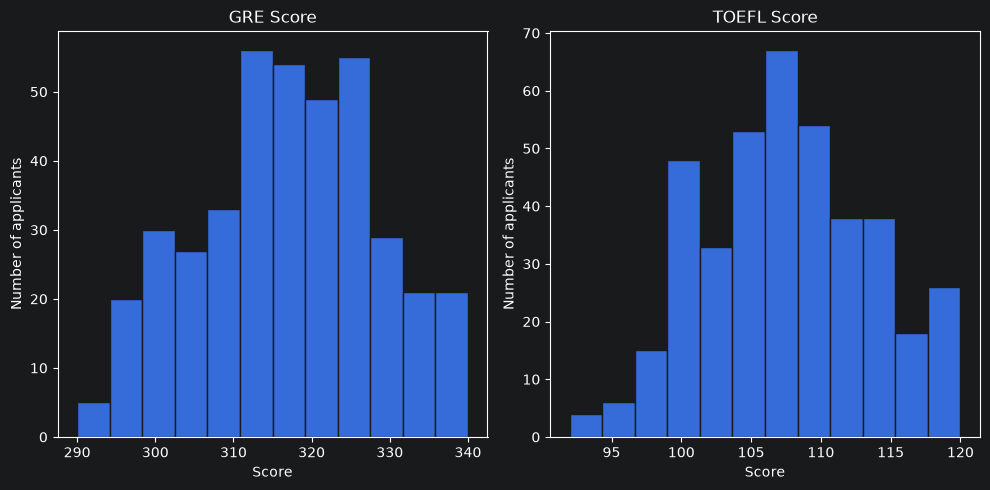

In [9]:
gre, toefl = df['GRE Score'], df['TOEFL Score']
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].hist(gre, bins=12, edgecolor='#181a1b')
ax[0].set_title('GRE Score')
ax[0].set_xlabel('Score')
ax[0].set_ylabel('Number of applicants')

ax[1].hist(toefl, bins=12, edgecolor='#181a1b')
ax[1].set_title('TOEFL Score')
ax[1].set_xlabel('Score')
ax[1].set_ylabel('Number of applicants')

plt.tight_layout()
plt.show()

Баллы GRE преимущественно сосредоточены в диапазоне 310-330, а TOEFL - 100-115. Низкие значения встречаются реже, но визуально не отделены от основной массы наблюдений.

In [10]:
# Создаём два признака: среднее SOP и LOR и произведение CGPA на Research
sop_lor_mean = df[['SOP', 'LOR ']].mean(axis=1)
df['SOP_LOR_Mean'] = sop_lor_mean

cgpa_research = df['CGPA'] * df['Research']
df['CGPA_Research'] = cgpa_research

In [11]:
# Разделяем датасет на train, valid, test
# x - фичи по которым предсказываем, y - целевая переменная, которую предсказываем (Chance of Admit)
x = df.drop(columns=['Chance of Admit ', 'Serial No.'])
y = df['Chance of Admit ']

# 60% train дата, 20% valid дата, 20% test дата
x_train_val, x_test, y_train_val, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

x_train, x_val, y_train, y_val = train_test_split(
    x_train_val, y_train_val, test_size=0.25, random_state=42
)

In [12]:
# Масштабируем признаки
scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)
x_val_scaled = scaler.transform(x_val)

In [13]:
# Обучаем линейную регрессию и получаем прогнозы на валидационной выборке
model = LinearRegression()

model.fit(x_train_scaled, y_train)

y_val_pred = model.predict(x_val_scaled)

# MAE
baseline_mae = mean_absolute_error(y_val, y_val_pred)

# RMSE
baseline_rmse = root_mean_squared_error(y_val, y_val_pred)

# R2
baseline_r2 = r2_score(y_val, y_val_pred)

print(f'Baseline MAE: {baseline_mae}, Baseline RMSE: {baseline_rmse}, Baseline R2: {baseline_r2}')

Baseline MAE: 0.05547474305133797, Baseline RMSE: 0.07627387699160704, Baseline R2: 0.6919646771830291


In [14]:
# Подбор гиперпараметров
alphas = [0.01, 0.1, 1, 10, 100]
results = []
for alpha in alphas:
    ridge_model = Ridge(alpha=alpha)

    ridge_model.fit(x_train_scaled, y_train)

    ridge_val_pred = ridge_model.predict(x_val_scaled)

    # RMSE Ridge
    ridge_rmse = root_mean_squared_error(y_val, ridge_val_pred)

    results.append({'alpha': alpha, 'RMSE': ridge_rmse})

results_df = pd.DataFrame(results)
results_df

,alpha,RMSE
0,0.01,0.076282
1,0.10,0.076338
2,1.00,0.076464
3,10.00,0.076196
4,100.00,0.077976


После подбора разных параметров alpha, минимальная RMSE на валидации получена при значении 10

In [15]:
# Прогоняем лучшее значение alpha, вместе с MAE, RMSE, R2
best_index = results_df['RMSE'].idxmin()
best_alpha = results_df.loc[best_index]['alpha']

best_model = Ridge(alpha=best_alpha)

best_model.fit(x_train_scaled, y_train)

best_val_pred = best_model.predict(x_val_scaled)

# MAE
best_mae = mean_absolute_error(y_val, best_val_pred)

# RMSE
best_rmse = root_mean_squared_error(y_val, best_val_pred)

# R2
best_r2 = r2_score(y_val, best_val_pred)

print(f'Best MAE: {best_mae}, Best RMSE: {best_rmse}, Best R2: {best_r2}')

Best MAE: 0.05491426528099874, Best RMSE: 0.07619589090675626, Best R2: 0.6925942554581813


In [16]:
# Оцениваем выбранную модель на тестовой выборке
test_pred = best_model.predict(x_test_scaled)

# MAE
test_mae = mean_absolute_error(y_test, test_pred)

# RMSE
test_rmse = root_mean_squared_error(y_test, test_pred)

# R2
test_r2 = r2_score(y_test, test_pred)

print(f'Test MAE: {test_mae}, Test RMSE: {test_rmse}, Test R2: {test_r2}')

Test MAE: 0.04819378151674503, Test RMSE: 0.06970476809824513, Test R2: 0.8118465291415969


Итоговое заключение

Проверены данные, созданы два новых признака и выполнено разделение на тренировочную, валидационную и тестовую выборки в пропорции 60/20/20. Масштабирование настроено только на тренировочных данных.

После сравнения базовой линейной регрессии и Ridge выбрана Ridge с alpha=10: она показала минимальную RMSE на валидации, хотя улучшение относительно базовой модели было небольшим.

На тестовой выборке получены MAE = 0,0482, RMSE = 0,0697, R2 = 0,8118. Прогнозы в среднем отличаются от значений вероятности зачисления в датасете примерно на 4,82 процентного пункта.